# Unequal Housing Conditions: EDA for Reactive & Proactive Datasets

## Summary

In April 2022, Health Affairs journal [published research](https://drive.google.com/file/d/1UNsZFoiROnXif1XU6L2_kiELQ-xJmMia/view?usp=share_link) correlating racial makeup of neighborhoods to unequal housing conditions and code enforcement related to asthma triggers. The researchers found that, when analyzing publicly-available 311 data between 2011 and 2021, predominantly white neighborhoods report fewer conditions known to cause or exacerbate asthma, and when they do, they experience faster case closure rates, fewer overdue requests, and higher chances of the request resulting in a repair. 

While the above study was predicated on the publicly-available 311 data where renters call to put in their complaints before the City react (we term this data as reactive dataset), there has been a policy which allows the [CIty to randomly inspect housing](https://www.boston.gov/departments/inspectional-services/inspecting-housing-boston) to ensure safety and protect the health of the public.

Thus, the inspectional service department developed [an algorithm](https://drive.google.com/file/d/1Cn444cCKTDTU2sqXXCiqzDLha3wGvczA/view?usp=drive_link) to randomly assign houses for inspection. This proactive approach would be analyze to explore and determine the efficacy of the policy as it pertains to ensuring equitable distribution of the City's housing safety protocols. 


## EDA Problem Statement

Datasets: 
* 311 Requests, 2020 - Present
* Proactive Inspections Data, 2020 - Present
* Reactive Inspections data, 2023 - Present

Explore the different features in the dataset to see if it will good for feature selection and determining feature importance.
* If possible, a predictive model could be developed to using property features, location & other factors as IVs.
* Graph Analysis; to connect different locations using various nodes and edges to gain insights into likely violators.
* Similarity Analysis/CLustering based on different features.



In [1]:
#####  Import libraries for Boston City DoIT Analytics database..
import os 
import civis

# import libraries for data pre-processing
import pandas as pd
import numpy as np
from datetime import datetime
import datetime as datetime

# import libraries for visualization
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from chart_studio import plotly
import plotly.offline as pyoff
import plotly.graph_objs as go
import plotly.express as px

# import libraries for geospatial analysis
import geopandas as gpd
import splot

from pysal.viz import splot
from splot.esda import plot_moran
import contextily
from IPython.display import display, Markdown, display_latex, display_markdown, display_html

# More packages for developing spatial hypothesis test.
from pysal.explore import esda
from pysal.lib import weights
from numpy.random import seed

from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
init_notebook_mode(connected=True)        # Display plot on notebook while the kernel is running


# utils
import warnings 
warnings.filterwarnings('ignore')


C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:39: NumbaDeprecationWarning:

The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.

C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:165: NumbaDeprecationWarning:

The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.

C:\Users\174006\boston-env\lib\site-packages\libpysal\cg\alpha_shapes.py:199: NumbaDeprecationWarning:

The 'nopython

In [2]:
### import os
#import civis
#import pandas as pd

os.environ['PYTHONPATH']='.'
os.environ['CIVIS_API_KEY']='BMHcrOhepkU6Wa-nZocM4Baf8IxVDecotXGyz8FLx14'

# Define the SQL query for proactive inspections from 2020 - present 
sql_proactive_inspections = """
SELECT * FROM isd_internal_data.proactive_inspections 
WHERE resultdttm >= '2020-01-01 00:00:00+00'
"""
# Define the SQL query for proactive violations from 2020 - present 
sql_proactive_violations = """
SELECT * FROM isd_internal_data.proactive_violations
WHERE resultdttm >= '2020-01-01 00:00:00+00'
"""

# Define the SQL query for reactive inspections/cases from 2023 - present 
sql_reactive_cases = """
SELECT * FROM isd_internal_data.reactive_cases
WHERE resultdttm >= '2023-01-01 00:00:00+00'
"""
# Define the SQL query for reactive violations from 2023 - present 
sql_reactive_violations = """
SELECT * FROM isd_internal_data.reactive_violations 
WHERE resdttm >= '2023-01-01 00:00:00+00'
"""

df_proactive_inspections = civis.io.read_civis_sql(sql_proactive_inspections,
                                            database='Boston',
                                            use_pandas=True)
df_proactive_violations = civis.io.read_civis_sql(sql_proactive_violations,
                                            database='Boston',
                                            use_pandas=True)
df_reactive_inspections = civis.io.read_civis_sql(sql_reactive_cases,
                                            database='Boston',
                                            use_pandas=True)
df_reactive_violations = civis.io.read_civis_sql(sql_reactive_violations,
                                            database='Boston',
                                            use_pandas=True)


In [3]:
df_proactive_inspections.head()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,gpsx,gpsy,gpsz,postdir,state,stname,stno,suffix,zip,gps_geom_2249
0,Condo,RINS-513784,"32 Sidlaw Road, Unit 11",2027-08-19 04:00:00+00,,NaN,HSNINTFC,2022-11-16 12:42:37.23+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
1,Condo,RINS-482490,NaN,2027-03-30 04:00:00+00,,NaN,HSNINTFC,2022-06-15 12:37:44.39+00,149929,149929,...,NaN,NaN,NaN,,,,,,,NaN
2,Condo,RINS-495004,Condo #70,2027-09-28 04:00:00+00,,NaN,HSNINTFC,2022-10-19 14:15:32.097+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
3,Condo,RINS-494981,NaN,2027-09-29 04:00:00+00,,NaN,HSNINTFC,2022-10-19 13:27:10.737+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
4,Condo,RINS-512546,NaN,2027-09-13 04:00:00+00,,NaN,HSNINTFC,2022-11-10 15:44:38.64+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN


In [4]:
sub = df_proactive_inspections[['apkey','licensecat','licenseno','addrkey','result','resultdttm','resultby','compdttm','descript','gpsx','gpsy','gps_geom_2249']]


In [ ]:
# Create a geometry column using 'gpsx' and 'gpsy', we could have used longitude and lat respectively if we had those instead.
# df_proactive_inspections['geometry'] = gpd.points_from_xy(df_proactive_inspections.gpsx, df_proactive_inspections.gpsy, crs=4326)

# Convert the pandas DataFrame to a geopandas GeoDataFrame
#gdf = gpd.GeoDataFrame(df_proactive_inspections, geometry='geometry', crs='EPSG:4326')
#gdf.head()

In [5]:
# Convert the pandas DataFrame to a geopandas GeoDataFrame
gdf = gpd.GeoDataFrame(sub, geometry=gpd.points_from_xy(sub.gpsx,sub.gpsy, crs=4326))

gdf.head()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
0,2634600,Condo,RINS-513784,1,Pass,2022-08-19 04:00:00+00,110163,NaN,Rental Unit Inspection,NaN,NaN,NaN,POINT EMPTY
1,2510902,Condo,RINS-482490,1,Pass,2022-03-30 04:00:00+00,149929,NaN,Rental Unit Inspection,NaN,NaN,NaN,POINT EMPTY
2,2601823,Condo,RINS-495004,1,Pass,2022-09-28 04:00:00+00,110163,NaN,Rental Unit Inspection,NaN,NaN,NaN,POINT EMPTY
3,2601697,Condo,RINS-494981,1,Pass,2022-09-29 04:00:00+00,110163,NaN,Rental Unit Inspection,NaN,NaN,NaN,POINT EMPTY
4,2631839,Condo,RINS-512546,1,Pass,2022-09-13 04:00:00+00,110163,NaN,Rental Unit Inspection,NaN,NaN,NaN,POINT EMPTY


In [6]:
gdf.tail()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
146505,2671814,MultiFam,RINS-520193,697480,Fail,2023-04-03 15:44:00+00,110900,2023-04-03 15:44:00+00,Rental Unit Inspection,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...,POINT (770981.90678 2951566.74263)
146506,2656482,MultiFam,RINS-518086,697548,Pass,2023-03-02 14:35:00+00,149875,2023-03-02 14:35:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146507,2656483,MultiFam,RINS-518087,697548,Pass,2023-03-17 14:23:00+00,110900,2023-03-17 14:23:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146508,2656484,MultiFam,RINS-518088,697548,Pass,2023-03-23 15:11:00+00,149505,2023-03-23 15:11:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146509,2656485,MultiFam,RINS-518089,697548,Pass,2023-03-27 14:10:00+00,149875,2023-03-27 14:10:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)


### Conducting EDA

Exploratory data analysis to dig deep in order to better understand basic information such as record counts, data types, and missingness etc. 


In [7]:
gdf.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 146510 entries, 0 to 146509
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype   
---  ------         --------------   -----   
 0   apkey          146510 non-null  int64   
 1   licensecat     146510 non-null  object  
 2   licenseno      146510 non-null  object  
 3   addrkey        146510 non-null  int64   
 4   result         146510 non-null  object  
 5   resultdttm     146510 non-null  object  
 6   resultby       146510 non-null  object  
 7   compdttm       141555 non-null  object  
 8   descript       146510 non-null  object  
 9   gpsx           146143 non-null  float64 
 10  gpsy           146143 non-null  float64 
 11  gps_geom_2249  146143 non-null  object  
 12  geometry       146510 non-null  geometry
dtypes: float64(2), geometry(1), int64(2), object(8)
memory usage: 14.5+ MB


There are 146510 records in the dataset with some columns having missing records.


In [8]:
# Get the unique values from the 'result' column
unique_results = gdf['result'].unique()
unique_results


array(['Pass', 'Fail', 'Hold', ' '], dtype=object)

Does **'Hold' and the empty strings** for results imply the inspection is yet to be completed? 
Maybe we combined both as incomplete IC and keep it in the analysis instead of the convenience of dropping both.


In [9]:
# Combine 'Hold' and ' ' categories and rename to 'IC', thus incomplete
gdf['result'] = gdf['result'].replace({'Hold': 'IC', ' ': 'IC'})
unique_results = gdf['result'].unique()
unique_results


array(['Pass', 'Fail', 'IC'], dtype=object)

In [10]:
# Convert 'Fail' to 0 and 'Pass' to 1 and 'IC' to 2
gdf['result'] = gdf['result'].map({'Fail': 0, 'Pass': 1, 'IC': 2})

# Print the unique values in the 'result' column to verify the changes
unique_results = gdf['result'].unique()
unique_results


array([1, 0, 2], dtype=int64)

In [11]:
# Calculate the count and percentage of the results

result_counts = gdf['result'].value_counts()
result_percentages = gdf['result'].value_counts(normalize=True) * 100

# Create a DataFrame to display the result
result_table = pd.DataFrame({'Count': result_counts, 'Percentage': result_percentages})

# Format the percentage column to display with two decimal places
result_table['Percentage'] = result_table['Percentage'].map('{:.2f}%'.format)

# Display the result table
print(result_table)


        Count Percentage
result                  
0       74737     51.01%
1       71723     48.95%
2          50      0.03%


#### Result Details
* Zero represents failed inspections, whereas One represent passed inspections
* There 51% failed inspections and approximately 49% passed inspections
* The 0.03% is Incomplete

#### Owner License Analysis

In [12]:
unique_license_category = gdf['licensecat'].unique()
df_unique_license_category = pd.DataFrame({'Unique License Category': unique_license_category})

# Display the DataFrame
print(df_unique_license_category)


  Unique License Category
0                   Condo
1                MultiFam
2                  1-3FAM
3                  4-6FAM
4                        
5                      SF


In [13]:
# Calculate the count and percentage of the owner's license category

license_category_counts = gdf['licensecat'].value_counts()
license_category_percentages = gdf['licensecat'].value_counts(normalize=True) * 100

# Create a DataFrame to display the license category
license_category_table = pd.DataFrame({'Count': license_category_counts, 'Percentage': license_category_percentages})

# Format the percentage column to display with two decimal places
license_category_table['Percentage'] = license_category_table['Percentage'].map('{:.2f}%'.format)

# Display the license category table
print(license_category_table)


             Count Percentage
licensecat                   
MultiFam    110224     75.23%
1-3FAM       15188     10.37%
4-6FAM       11729      8.01%
              6188      4.22%
Condo         2991      2.04%
SF             190      0.13%


We have more Multi family houses (75%) but 6186 (4.23%) of the units were not categorized
Is the default a MultiFamily house or we'd be better off dropping this records?
* I will leave it in for now.


### Visual Exploration between Categorical Variables


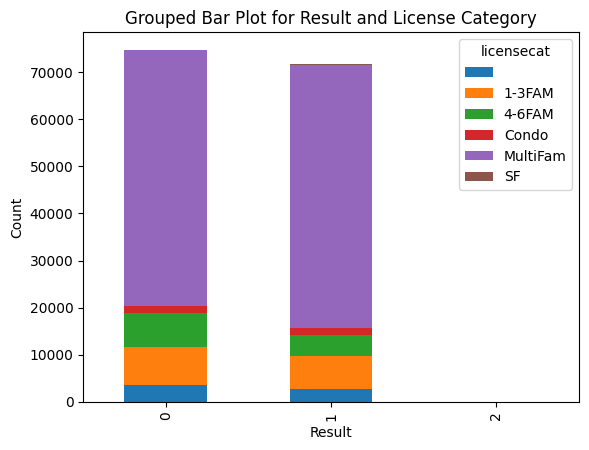

In [14]:
# Group the data by 'result' and 'licensecat', and count the occurrences
grouped_data = gdf.groupby(['result', 'licensecat']).size().unstack()

# Plot the grouped bar plot
grouped_data.plot(kind='bar', stacked=True)

# Add labels and title to the plot
plt.xlabel('Result')
plt.ylabel('Count')
plt.title('Grouped Bar Plot for Result and License Category')

# Show the plot
plt.show()


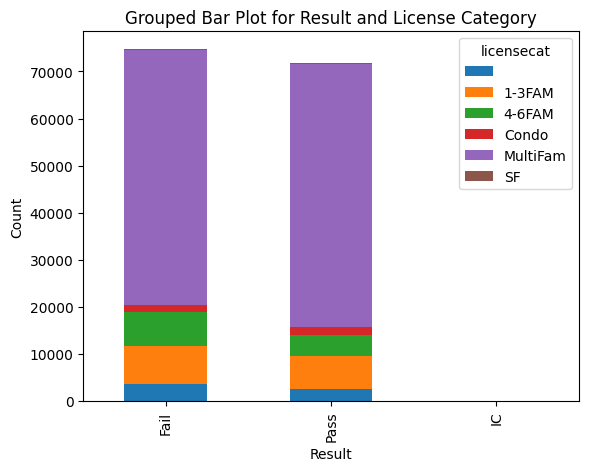

In [15]:
# Group the data by 'result' and 'licensecat', and count the occurrences
grouped_data = gdf.groupby(['result', 'licensecat']).size().unstack()

# Plot the grouped bar plot
ax = grouped_data.plot(kind='bar', stacked=True)

# Add labels and title to the plot
plt.xlabel('Result')
plt.ylabel('Count')
plt.title('Grouped Bar Plot for Result and License Category')

# Rename the x-axis tick labels
ax.set_xticklabels(['Fail', 'Pass', 'IC'])

# Show the plot
plt.show()


### Exploratory Spatial Data Analysis ESDA
* Looked at on **ArcGIS Pro** 


In [ ]:
# Drop all rows with NaN values in the 'gpsx' column
# gdf = gdf.dropna(subset=['gpsx'])
# Reset the index to begin from 0
# gdf = gdf.reset_index(drop=True)

# gdf_sub.tail()

### Hypothesis Testing and Spatial Randomness
#### Hypothesis Testing and Spatial Randomness

* A **spatial structure** is the presence of a pattern within data across geographic space. Data that has no spatial structure is said to have been generated by an **independent random process (IRP).** 
* This **IRP** result is data that exhibits **complete spatial randomness (CSR).** 
* IRP and CSR used interchangeably. IRP/CSR must satisfy two conditions in order to construct a valid hypothesis test:

1. Any observation must have an equal probability of occurring in any location, Thus, it vary from place to place based on changes in the underlying area. This is known as a **first-order effect**. As an example, the distribution of an infectious disease will vary across a study area, based on underlying environmental factors.
2. The location of an observation is independent and does not impact the location of any other observation, thus, it varies from place to place due to interaction effects between observations.. This is known as a **second-order effect.** To continue the previous example on infectious diseases, the intensity of the disease is expected to vary and is dependent on locations where there are infected people, whereas other infections will cluster around the infected people.

In our domain for analyzing asthma triggers in Greater Boston, the **first-order effect** will be the distrition of the housing code violations for rodents and mold (which are known to be asthma triggers) in the City.
While the **second-order effect** is the variation of the degree of violations and how dependent it is on locations where there are most violations.

#### Hypothesis 
* H0: The data is distributed randomly across space.
* Ha: The data exhibits a spatial structure and is not randomly distributed.

#### Using Moran’s I
**Moran’s I** measures spatial autocorrelation of data based on feature values and feature locations. 
Spatial autocorrelation measures the variation of a variable by taking an observation and seeing how similar or different it is compared to other observations within its neighborhood. 


### Global Spatial Autocorrelation


In [17]:
# Convert POINT geometries to Polygon format with buffer distance of 0 (essentially converting points to polygons)
gdf['geometry'] = gdf['geometry'].buffer(0)


In [18]:
# Calculate the Queen's weights
w = weights.Queen.from_dataframe(gdf)


In [19]:
# Row-standardization
w.transform = 'R'


('WARNING: ', 0, ' is an island (no neighbors)')
('WARNING: ', 1, ' is an island (no neighbors)')
('WARNING: ', 2, ' is an island (no neighbors)')
('WARNING: ', 3, ' is an island (no neighbors)')
('WARNING: ', 4, ' is an island (no neighbors)')
('WARNING: ', 5, ' is an island (no neighbors)')
('WARNING: ', 6, ' is an island (no neighbors)')
('WARNING: ', 7, ' is an island (no neighbors)')
('WARNING: ', 8, ' is an island (no neighbors)')
('WARNING: ', 9, ' is an island (no neighbors)')
('WARNING: ', 10, ' is an island (no neighbors)')
('WARNING: ', 11, ' is an island (no neighbors)')
('WARNING: ', 12, ' is an island (no neighbors)')
('WARNING: ', 13, ' is an island (no neighbors)')
('WARNING: ', 14, ' is an island (no neighbors)')
('WARNING: ', 15, ' is an island (no neighbors)')
('WARNING: ', 16, ' is an island (no neighbors)')
('WARNING: ', 17, ' is an island (no neighbors)')
('WARNING: ', 18, ' is an island (no neighbors)')
('WARNING: ', 19, ' is an island (no neighbors)')
('WARNING:

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



In [25]:
# Calculate the spatial lag
gdf['result_lag'] = weights.spatial_lag.lag_spatial(w, gdf['result'])

# Standardize the variable of interest and the lag variable
gdf['result_std'] = (gdf['result'] - gdf['result'].mean())
gdf['result_lag_std'] = (gdf['result_lag'] - gdf['result_lag'].mean())


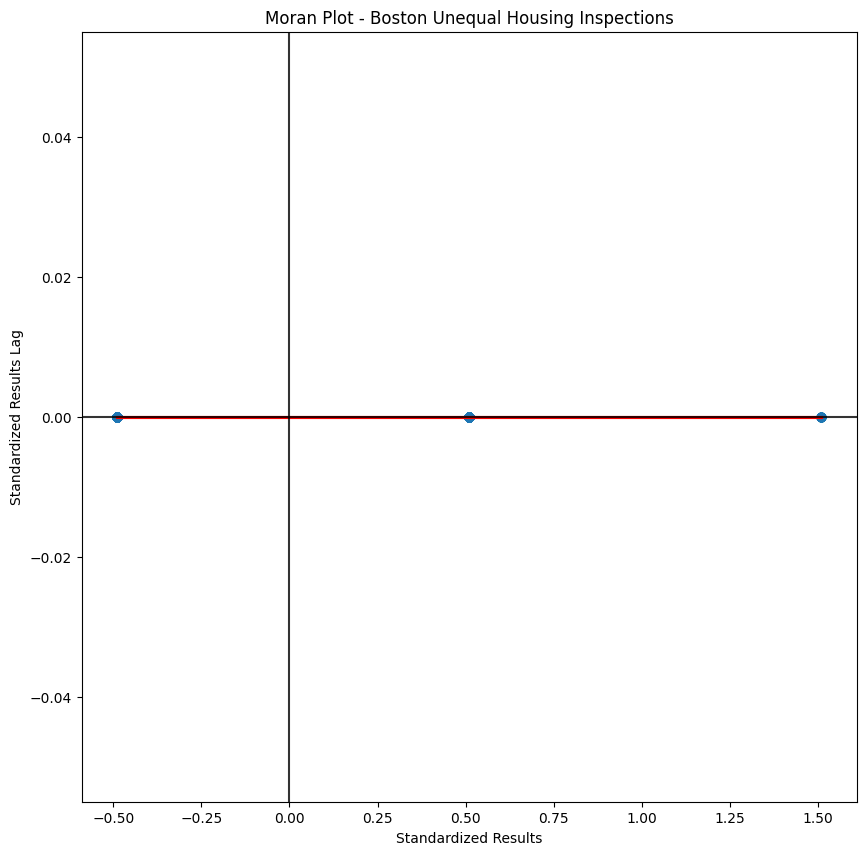

In [27]:
f, ax = plt.subplots(1, figsize=(10, 10))
sns.regplot(
    x='result_std', # variable of interest
    y='result_lag_std', # spatial lag
    ci=None, # suppress the plotting of the confidence interval
    data=gdf, # dataset
    line_kws={'color':'r'}
)

ax.axvline(0, c='k', alpha=0.8)
ax.axhline(0, c='k', alpha=0.8)

ax.set_title('Moran Plot - Boston Unequal Housing Inspections')
ax.set_xlabel('Standardized Results')
ax.set_ylabel('Standardized Results Lag')
plt.show()


In [28]:
morans_stat = esda.moran.Moran(gdf['result'], w)
display(Markdown(f"""**Morans I:** {morans_stat.I}"""))
display(Markdown(f"""**p-value:** {morans_stat.p_sim}"""))


**Morans I:** nan

**p-value:** 0.001

(<Figure size 1000x400 with 2 Axes>,
 array([<Axes: title={'center': 'Reference Distribution'}, xlabel='Moran I: nan', ylabel='Density'>,
        <Axes: title={'center': 'Moran Scatterplot (nan)'}, xlabel='Attribute', ylabel='Spatial Lag'>],
       dtype=object))

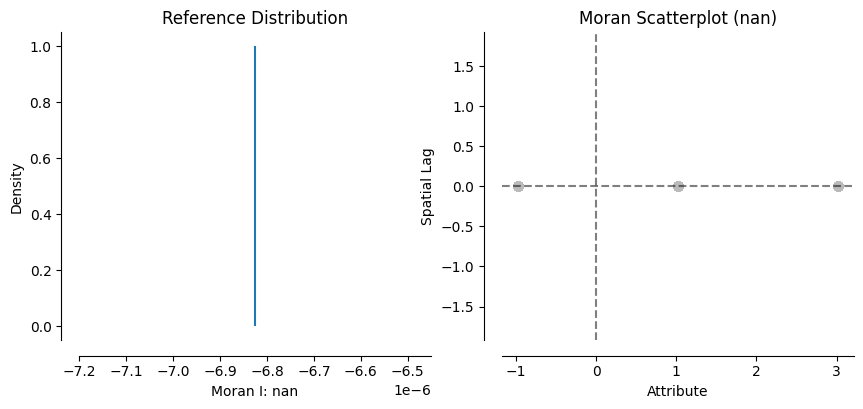

In [29]:
plot_moran(morans_stat)


This does not seem like a good metric for this categorical variables that we have. Works better with continues variables.


In [39]:
# Drop rows with empty or invalid geometries
gdf = gdf.dropna(subset=['geometry'])


In [41]:
# Check the number of observations in the 'geometry' and 'result' columns
num_geometry_observations = len(gdf['geometry'])
num_result_observations = len(gdf['result'])

# Compare the number of observations
if num_geometry_observations == num_result_observations:
    print("The 'geometry' and 'result' columns have the same number of observations.")
else:
    print("The 'geometry' and 'result' columns have different numbers of observations.")


The 'geometry' and 'result' columns have the same number of observations.


In [ ]:
# Perform the Local Spatial Autocorrelation (Moran's I) on the categorical column
moran_loc = Moran_Local(gdf['result'], w)

# Access the Moran's I Local statistic, z-scores, and p-values
moran_loc_I = moran_loc.Is
moran_loc_z_sim = moran_loc.z_sim
p_values = moran_loc.p_sim

# Print the results
print("Moran's I Local:", moran_loc_I)
print("Z-scores:", moran_loc_z_sim)
print("p-values:", p_values)


In [ ]:
# More packages for developing spatial hypothesis test.
from pysal.explore import esda
from pysal.lib import weights
from numpy.random import seed


In [ ]:
import numpy as np
from esda.moran import Moran

# Convert the 'licensecat' column to category dtype
gdf['licensecat'] = gdf['licensecat'].astype('category')

# Set seed for reproducibility
np.random.seed(54321)

# Set the variables of interest
variables_of_interest = ['licensecat','result']

for voi in variables_of_interest:
    morans_stat = esda.moran.Moran(gdf[voi], w)
    display(Markdown(f"""**Morans I for {voi}:** {morans_stat.I}"""))
    display(Markdown(f"""**p-value for {voi}:** {morans_stat.p_sim}"""))
    plot_moran(morans_stat)
    

### Point PatterN Analysis
This centers around the patterns present within point data instead of the attributes associated with the point data.
* This is quintessential in studies of infectious diseases, helps check whether diseases are clustered together around infected individuals or areas.

#### Ripley’s alphabet functions


In [44]:
# Spatial Statistics
from pointpats import distance_statistics, QStatistic, random, PointPattern, PoissonPointProcess, PoissonClusterPointProcess, Window, poly_from_bbox
import libpysal as ps
from libpysal.cg import shapely_ext

# Setting matplotlib jupyter options to show plots in notebook
%matplotlib inline

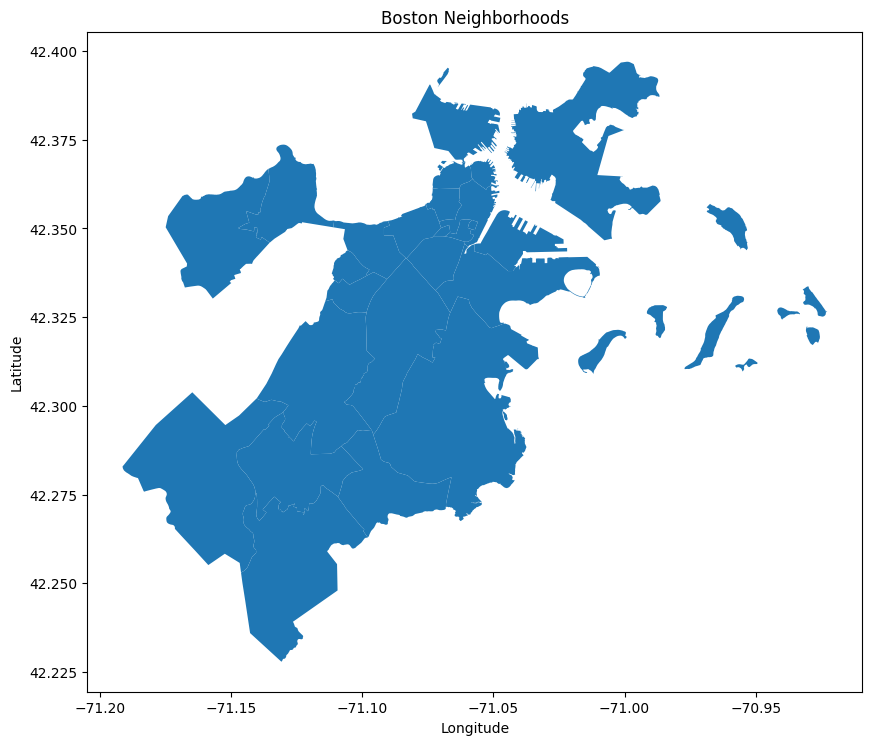

In [51]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Replace the file path with your actual file path
shapefile_path = r"C:\Users\174006\Desktop\Boston\Boston_Neighborhoods.shp"

def plot_shapefile(shapefile_path):
    # Read the shapefile using geopandas
    gdf = gpd.read_file(shapefile_path)

    # Plot the map
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf.plot(ax=ax)
    plt.title("Boston Neighborhoods")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.show()

# Call the function to plot the map
plot_shapefile(shapefile_path)


In [53]:
# Replace the file path with your actual file path
shapefile_path = r"C:\Users\174006\Desktop\Boston\Boston_Neighborhoods.shp"
boston = gpd.read_file(shapefile_path)
boston_city = boston.dissolve()
boston_city


,geometry,OBJECTID,Name,Acres,Neighborho,SqMiles,ShapeSTAre,ShapeSTLen
0,"MULTIPOLYGON (((-71.06838 42.27084, -71.06841 ...",27,Roslindale,1605.568237,15,2.51,6.993827e+07,53563.912597


In [60]:
# Access shapefile of the state of ohio
bn = ps.io.open(shapefile_path)
polys = [shp for shp in bn]


In [61]:
city = shapely_ext.cascaded_union(polys)

# create window from boston city boundary
window = Window(city.parts)


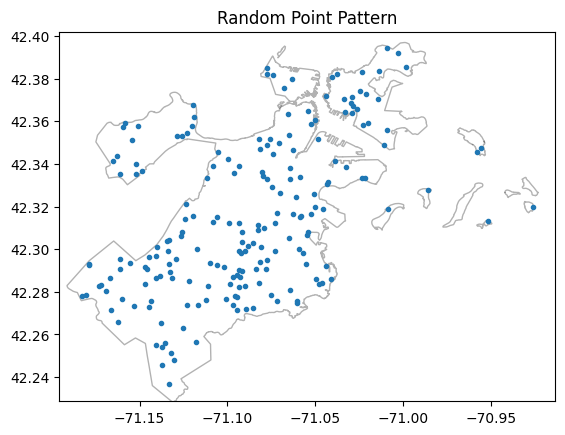

In [62]:
# Here, we're simulating a csr process in the window being Boston (200 points, 1 realization)
# setting "asPP" True generates a point pattern
# setting "conditioning" to false simulates a N-conditioned CSR
np.random.seed(5)
samples = PoissonPointProcess(window, 200, 1, conditioning=False, asPP=True)

pp_csr = samples.realizations[0] # simulated point pattern

pp_csr.plot(window=True, hull=False, title='Random Point Pattern')


The above figure may appear to be somewhat clustered and not look like randomly derived data. 
This is because the human brain is built to try and detect patterns, and it wants to see a pattern in this data. 
However, this data is generated by taking random points from a Poisson distribution.


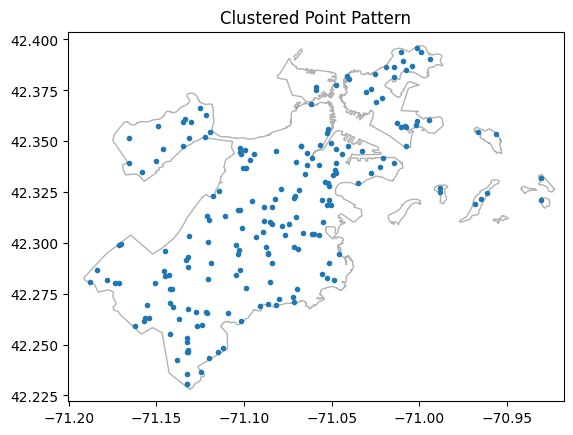

In [64]:
np.random.seed(10)
csamples = PoissonClusterPointProcess(window, 200, 5, 0.5, 1, asPP=True)
pp_pcp = csamples.realizations[0]
pp_pcp.plot(window=True, hull=False, title='Clustered Point Pattern')


In [124]:
# Convert the pandas DataFrame to a geopandas GeoDataFrame
gdf_new = gpd.GeoDataFrame(
    sub, geometry=gpd.points_from_xy(sub.gpsx,sub.gpsy),
    crs="EPSG:4326"
)


In [125]:
# Step 1: Define a function to check if the geometry is empty or contains 'POINT EMPTY'.
def is_invalid_geometry(geom):
    return geom.is_empty or geom.geom_type == 'POINT EMPTY'

# Step 2: Use the defined function to create a boolean mask for invalid geometries and NaN values.
mask_invalid_geometries = gdf_new['geometry'].apply(is_invalid_geometry)
mask_nan_values = gdf_new['geometry'].isna()

# Step 3: Combine the boolean masks using logical OR (|).
mask_invalid_rows = mask_invalid_geometries | mask_nan_values

# Step 4: Use the mask to filter out the rows with invalid geometries and NaN values.
gdf_new = gdf_new[~mask_invalid_rows]
gdf_new.head(20)


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
24,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
25,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
26,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
27,2436039,1-3FAM,RINS-468096,158813,Pass,2022-03-16 15:50:00+00,163574,2022-03-16 15:50:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
28,2436040,1-3FAM,RINS-468097,158813,Pass,2022-03-16 15:51:00+00,163574,2022-03-16 15:51:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340)
29,2631787,1-3FAM,RINS-512533,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
30,2631787,1-3FAM,RINS-512533,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
31,2631788,1-3FAM,RINS-512534,158846,Pass,2022-12-08 16:12:00+00,122496,2022-12-08 16:12:00+00,Rental Unit Inspection,783724.783078,2.963659e+06,0101000020C90800007C8CEF90D9EA27419F04364F659C...,POINT (783724.78308 2963658.61884)
32,2323666,1-3FAM,RINS-456732,158901,Fail,2021-08-19 17:03:00+00,75622,2021-08-19 17:03:00+00,Rental Unit Inspection,783461.412325,2.963695e+06,0101000020C90800007D4F1CD3CAE82741D7202388779C...,POINT (783461.41233 2963695.06357)
33,2323666,1-3FAM,RINS-456732,158901,Fail,2021-08-19 17:03:00+00,75622,2021-08-19 17:03:00+00,Rental Unit Inspection,783461.412325,2.963695e+06,0101000020C90800007D4F1CD3CAE82741D7202388779C...,POINT (783461.41233 2963695.06357)


In [126]:
gdf_new.tail()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry
146505,2671814,MultiFam,RINS-520193,697480,Fail,2023-04-03 15:44:00+00,110900,2023-04-03 15:44:00+00,Rental Unit Inspection,770981.906785,2.951567e+06,0101000020C9080000411546D04B87274180790E5FC784...,POINT (770981.90678 2951566.74263)
146506,2656482,MultiFam,RINS-518086,697548,Pass,2023-03-02 14:35:00+00,149875,2023-03-02 14:35:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146507,2656483,MultiFam,RINS-518087,697548,Pass,2023-03-17 14:23:00+00,110900,2023-03-17 14:23:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146508,2656484,MultiFam,RINS-518088,697548,Pass,2023-03-23 15:11:00+00,149505,2023-03-23 15:11:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)
146509,2656485,MultiFam,RINS-518089,697548,Pass,2023-03-27 14:10:00+00,149875,2023-03-27 14:10:00+00,Rental Unit Inspection,766534.502239,2.923061e+06,0101000020C90800000F8525018D642741B0DBCE7E1A4D...,POINT (766534.50224 2923060.99069)


In [128]:
import pyproj

# Define the EPSG code for the UTM coordinate system used in the 'gpsx' and 'gpsy' columns.
epsg_code_utm = '32618'

# Define the EPSG code for the WGS 84 (latitude-longitude) coordinate system.
epsg_code_wgs84 = '4326'

# Create a Proj transformer to convert from UTM to WGS 84.
transformer = pyproj.Transformer.from_crs(epsg_code_utm, epsg_code_wgs84, always_xy=True)

# Convert 'gpsx' and 'gpsy' to latitude (X) and longitude (Y) columns.
gdf_new['X'], gdf_new['Y'] = transformer.transform(gdf_new['gpsx'].values, gdf_new['gpsy'].values)
gdf_new.head()


,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry,X,Y
24,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
25,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
26,2436038,1-3FAM,RINS-468095,158813,Pass,2022-03-16 15:49:00+00,163574,2022-03-16 15:49:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
27,2436039,1-3FAM,RINS-468096,158813,Pass,2022-03-16 15:50:00+00,163574,2022-03-16 15:50:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665
28,2436040,1-3FAM,RINS-468097,158813,Pass,2022-03-16 15:51:00+00,163574,2022-03-16 15:51:00+00,Rental Unit Inspection,782594.196709,2.963528e+06,0101000020C908000000FCB66404E22741B5466FE0239C...,POINT (782594.19671 2963527.75340),-72.158295,26.764665


<Axes: >

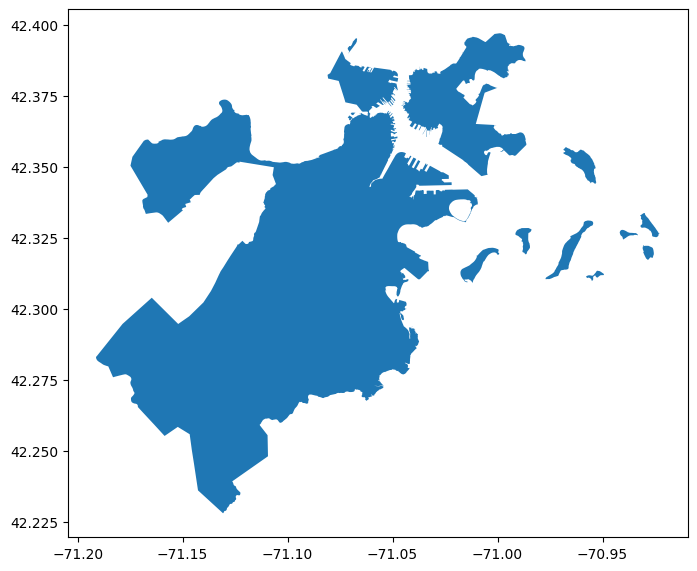

In [143]:
f, ax = plt.subplots(1, figsize=(8, 8))
boston_city.plot(ax = ax,color=None, zorder=1)


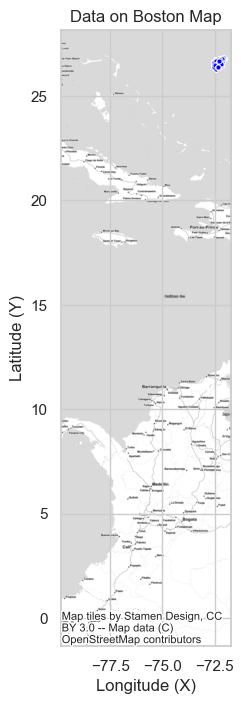

In [151]:
import contextily as ctx

# Create a joint plot using seaborn with 'X' (longitude) and 'Y' (latitude) columns from 'gdf_new'.
sns.set(style='whitegrid')
plt.figure(figsize=(10, 8))

# Use 'point' for marker instead of 'o'.
sns.scatterplot(data=gdf_new, x='X', y='Y', marker='.', color='blue', s=50, alpha=0.7)

# Add the basemap of Boston using contextily.
ctx.add_basemap(ax=plt.gca(), crs=gdf_new.crs.to_string(), source=ctx.providers.Stamen.TonerLite)

# Set aspect ratio to equal to prevent stretching of latitude axis.
plt.gca().set_aspect('equal')

# Show the plot.
plt.title('Data on Boston Map')
plt.xlabel('Longitude (X)')
plt.ylabel('Latitude (Y)')
plt.show()


ValueError: cannot convert float NaN to integer

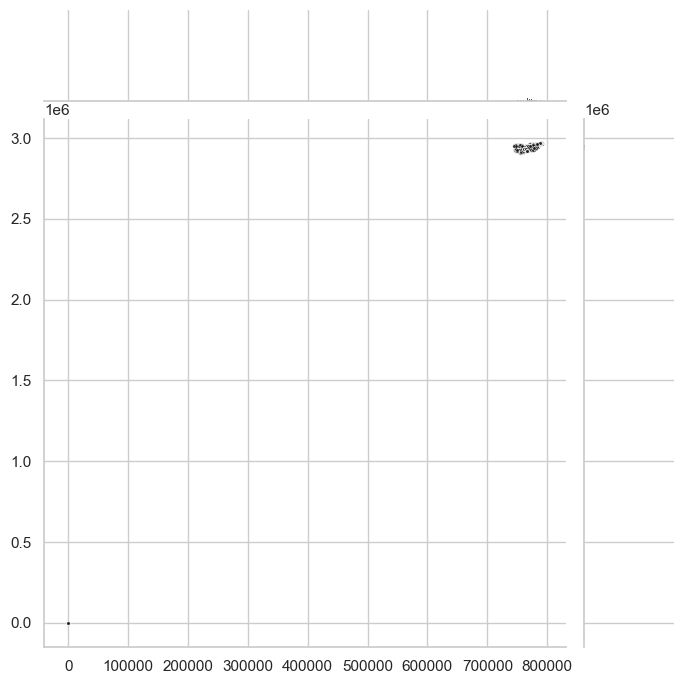

In [153]:
# Create a better visualization
joint_axes = sns.jointplot(
    x=gdf_new.geometry.x, 
    y=gdf_new.geometry.y, 
    data=gdf_new, 
    s=5, 
    height=7,
color='k');

contextily.add_basemap(
    joint_axes.ax_joint,
    crs="EPSG:4326",
    source=contextily.providers.Stamen.TonerLite
);


In [104]:
# Step 1: Extract 'gpsx' and 'gpsy' as 1D arrays from the GeoDataFrame.
gpsx_values = gdf['gpsx'].to_numpy()
gpsy_values = gdf['gpsy'].to_numpy()

# Step 2: Create a point pattern using the 'gpsx' and 'gpsy' coordinates.
point_pattern = pointpats.PointPattern(gpsx_values, gpsy_values)

# Step 3: Calculate Ripley's G function using the 'g_test()' function.
ripley_g = pointpats.g_test(point_pattern)

# The variable 'ripley_g' now contains the result of the G function test, including observed and expected values.

# You can access the observed and expected values from the 'ripley_g' variable as follows:
observed = ripley_g.observed
expected = ripley_g.expected

# You can also calculate the G function values for different distances using 'ripley_g.d'.
g_values = np.array(ripley_g.d)

# The 'g_values' variable now co

ValueError: Length mismatch: Expected axis has 1 elements, new values have 2 elements

In [ ]:
# Step 1: Drop 'POINT EMPTY' rows
gdf_new = gdf_new[~gdf_new.geometry.is_empty]

# Step 2: Convert 'geometry' column to Point geometries (assuming they are points representing centroids of polygons)
gdf_new['geometry'] = gdf_new.apply(lambda row: Point(row.geometry), axis=1)

# Step 3: Check and set the CRS of GeoDataFrames (if they are not already the same)
if gdf_new.crs != boston_city.crs:
    gdf_new = gdf_new.to_crs(boston_city.crs)

# Step 4: Plot the data from 'gdf_new' on the 'boston_city' map with contextily basemap
fig, ax = plt.subplots(figsize=(10, 10))
boston_city.plot(ax=ax, color='lightgrey', edgecolor='black')
gdf_new.plot(ax=ax, color='red', alpha=0.5, markersize=50)

# Add contextily basemap
contextily.add_basemap(ax, crs=boston_city.crs, source=contextily.providers.Stamen.Terrain)

# Apply seaborn styling
sns.set_style('whitegrid')

plt.title("Unequal Housing Data on Boston Map")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [106]:
gdf.tail(20)

,apkey,licensecat,licenseno,addrkey,result,resultdttm,resultby,compdttm,descript,gpsx,gpsy,gps_geom_2249,geometry,result_lag,result_std,result_lag_std
146490,2656478,MultiFam,RINS-518082,697411,1,2022-12-29 16:24:00+00,170713,2022-12-29 16:24:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0
146491,2187006,1-3FAM,RINS-439390,697427,0,2021-05-03 19:01:00+00,134922,2021-05-03 19:01:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146492,2187006,1-3FAM,RINS-439390,697427,1,2021-09-30 15:23:00+00,149875,2021-09-30 15:23:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,0.509774,0.0
146493,2187006,1-3FAM,RINS-439390,697427,0,2020-12-16 16:33:00+00,149875,2020-12-16 16:33:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146494,2187006,1-3FAM,RINS-439390,697427,0,2021-07-09 14:11:00+00,122496,2021-07-09 14:11:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146495,2187006,1-3FAM,RINS-439390,697427,0,2021-06-07 18:14:00+00,134922,2021-06-07 18:14:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146496,2187006,1-3FAM,RINS-439390,697427,0,2021-08-25 14:55:00+00,148496,2021-08-25 14:55:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,-0.490226,0.0
146497,2187006,1-3FAM,RINS-439390,697427,1,2023-01-18 19:14:00+00,149875,2023-01-18 19:14:00+00,Rental Unit Inspection,777563.975642,2.938006e+06,0101000020C9080000014987F3B7BA27414C787CCA4A6A...,POLYGON EMPTY,0.0,0.509774,0.0
146498,2656479,MultiFam,RINS-518083,697447,1,2023-01-26 18:34:00+00,149875,2023-01-26 18:34:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0
146499,2656480,MultiFam,RINS-518084,697455,1,2023-01-30 16:10:00+00,149505,2023-01-30 16:10:00+00,Rental Unit Inspection,766575.515401,2.923028e+06,0101000020C9080000619AE207DF642741B0DBCEE4094D...,POLYGON EMPTY,0.0,0.509774,0.0


In [3]:
df_proactive_inspections.head()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,gpsx,gpsy,gpsz,postdir,state,stname,stno,suffix,zip,gps_geom_2249
0,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
1,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
2,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
3,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN
4,MultiFam,RINS-494739,NaN,2027-10-07 04:00:00+00,,NaN,HSNINTFC,2022-10-14 15:23:37.48+00,110163,110163,...,NaN,NaN,NaN,,,,,,,NaN


In [4]:
df_proactive_inspections.tail()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,gpsx,gpsy,gpsz,postdir,state,stname,stno,suffix,zip,gps_geom_2249
145831,MultiFam,RINS-520193,NaN,NaN,,NaN,149875,2023-06-06 19:25:27.11+00,149929,149929,...,770981.906785,2.951567e+06,NaN,4,MA,Dartmouth,109,St,2116,0101000020C9080000411546D04B87274180790E5FC784...
145832,MultiFam,RINS-518089,NaN,2028-03-27 14:10:00+00,,NaN,149875,2023-03-27 14:10:39.813+00,149929,149929,...,766534.502239,2.923061e+06,NaN,18,MA,River,466,St,2126,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
145833,MultiFam,RINS-518088,NaN,2028-03-23 15:11:00+00,,NaN,149505,2023-03-23 15:25:54.6+00,149929,149929,...,766534.502239,2.923061e+06,NaN,18,MA,River,466,St,2126,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
145834,MultiFam,RINS-518087,NaN,2028-03-17 14:23:00+00,,NaN,110900,2023-03-17 14:23:55.813+00,149929,149929,...,766534.502239,2.923061e+06,NaN,18,MA,River,466,St,2126,0101000020C90800000F8525018D642741B0DBCE7E1A4D...
145835,MultiFam,RINS-518086,NaN,2028-03-02 14:35:00+00,,NaN,149875,2023-03-02 14:44:07.443+00,149929,149929,...,766534.502239,2.923061e+06,NaN,18,MA,River,466,St,2126,0101000020C90800000F8525018D642741B0DBCE7E1A4D...


In [5]:
df_proactive_violations.head()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,instripkey,refno_licinsp,mobileemp,mobiledttm,mobile_licinsp,inspbyprovider,resultbyprovider,aplicdefnkey_lictype,aplictypecatkey,licensenoprefix
0,FS,79720,NaN,2024-01-01 04:59:00+00,,2012-09-13 13:29:17+00,051219,2023-06-27 12:35:54.347+00,,051130,...,1,M637705230657030333,,2021-10-22 18:11:05+00,N,1,1,1000,1,NaN
1,FS,79720,NaN,2024-01-01 04:59:00+00,,2012-09-13 13:29:17+00,051219,2023-06-27 12:35:54.347+00,,051130,...,1,M637705230657030333,,2021-10-22 18:11:05+00,N,1,1,1000,1,NaN
2,FT,351027,NaN,2024-01-01 04:59:00+00,149057,2019-09-23 16:08:34+00,106365,2023-03-15 12:33:01.18+00,HSNINTFC,051130,...,1,M637366458610850327,,2020-09-25 15:51:01+00,N,1,1,1000,1,NaN
3,FT,351027,NaN,2024-01-01 04:59:00+00,149057,2019-09-23 16:08:34+00,106365,2023-03-15 12:33:01.18+00,HSNINTFC,051130,...,1,M637366458610850327,,2020-09-25 15:51:01+00,N,1,1,1000,1,NaN
4,FT,351027,NaN,2024-01-01 04:59:00+00,149057,2019-09-23 16:08:34+00,106365,2023-03-15 12:33:01.18+00,HSNINTFC,051130,...,1,M637366458610850327,,2020-09-25 15:51:01+00,N,1,1,1000,1,NaN


In [6]:
df_proactive_violations.tail()


,licensecat,licenseno,comments_licappl,expdttm,issby,issdttm,modby_licappl,moddttm_licappl,licenseby,addby_licappl,...,instripkey,refno_licinsp,mobileemp,mobiledttm,mobile_licinsp,inspbyprovider,resultbyprovider,aplicdefnkey_lictype,aplictypecatkey,licensenoprefix
251722,1-3FAM,RINS-531020,NaN,NaN,,NaN,110900,2023-07-06 15:57:29.667+00,113519,113519,...,1,NaN,,NaN,N,1,1,1029,1003,RINS-
251723,1-3FAM,RINS-531020,NaN,NaN,,NaN,110900,2023-07-06 15:57:29.667+00,113519,113519,...,1,NaN,,NaN,N,1,1,1029,1003,RINS-
251724,1-3FAM,RINS-531020,NaN,NaN,,NaN,110900,2023-07-06 15:57:29.667+00,113519,113519,...,1,NaN,,NaN,N,1,1,1029,1003,RINS-
251725,1-3FAM,RINS-531020,NaN,NaN,,NaN,110900,2023-07-06 15:57:29.667+00,113519,113519,...,1,NaN,,NaN,N,1,1,1029,1003,RINS-
251726,1-3FAM,RINS-531020,NaN,NaN,,NaN,110900,2023-07-06 15:57:29.667+00,113519,113519,...,1,NaN,,NaN,N,1,1,1029,1003,RINS-


As of July 10, 2023, the total number of proactive_inspections is 144948 while the total number of proactive_violations is 249,429. If the violations is from the overall inspections, I expected the violations to be less than the inspections.


In [7]:
df_reactive_inspections.head()


,addby,adddttm,apby,apcasekey,apcaseprocessstatekey,apno,casegrp,caseinfostatus,casename,comments,...,empid,emplast,empmid,supr,suprflag,adddttm_fy,full_address,full_address_w_ward,typeno_translation_et,gps_geom_2249
0,172905,2023-05-01 12:31:12.477+00,172905,673639,1163,HVIOL-673639,GENERAL,Closed,101004805333,NaN,...,,NaN,NaN,,N,2022,12June ST,12June ST 18,NaN,0101000020C90800007DE81A8CEA09274122E65018A852...
1,172905,2023-05-01 18:20:58.39+00,172905,673720,1160,HVIOL-673720,GENERAL,Open,101004806921,NaN,...,075702,Moore,NaN,,N,2022,31Ellington ST,31Ellington ST 14,01:00:00,0101000020C908000080BFB6937E752741806841830765...
2,172905,2023-05-02 15:08:26.687+00,172905,673902,1162,HVIOL-673902,GENERAL,Closed,101004808027,NaN,...,075702,Moore,NaN,,N,2022,71Esmond ST,71Esmond ST 14,09:00:00,0101000020C908000000A2631C8E75274104F0E443EB61...
3,113519,2023-04-04 17:16:15.533+00,113519,669734,1160,HVIOL-669734,,Open,101004762796,NaN,...,075702,Moore,NaN,,N,2022,289Hancock ST,289Hancock ST 15,15:38:00,0101000020C90800008290EAAB93AA274197FD5B81B769...
4,168316,2022-05-17 14:42:35.14+00,168316,614647,1162,HVIOL-614647,HOU,Closed,101004271190,NaN,...,075702,Moore,NaN,,N,2021,134Ballou AVE,134Ballou AVE 14,13:00:00,0101000020C90800007E4047F965762741440666344A58...


In [8]:
df_reactive_inspections.tail()


,addby,adddttm,apby,apcasekey,apcaseprocessstatekey,apno,casegrp,caseinfostatus,casename,comments,...,empid,emplast,empmid,supr,suprflag,adddttm_fy,full_address,full_address_w_ward,typeno_translation_et,gps_geom_2249
35639,51730,2023-05-02 06:29:41.23+00,51730,673751,1144,CE673751,,Open,NaN,NaN,...,051730,Cintolo,NaN,,N,2022,436Commercial ST,436Commercial ST 03,02:29:41,0101000020C9080000040BE69234B62741457C8E2F9593...
35640,51730,2023-03-30 04:50:34.957+00,51730,668853,1104,CE668853,,Closed,NaN,NaN,...,051730,Cintolo,NaN,,N,2022,103 to 107South ST,103 to 107South ST 03,00:50:37,0101000020C90800006758271B8DAC2741090CA3DC5E88...
35641,51730,2023-03-30 04:58:37.643+00,51730,668857,1144,CE668857,,Open,NaN,NaN,...,051730,Cintolo,NaN,,N,2022,25 to 29Beach ST,25 to 29Beach ST 03,00:58:39,0101000020C9080000000490BBA5A3274175DE6B754388...
35642,51730,2023-03-30 07:32:14.31+00,51730,668875,1144,CE668875,,Open,NaN,NaN,...,051730,Cintolo,NaN,,N,2022,403Fourth ST,403Fourth ST 06,03:32:15,0101000020C90800007C572D9464BF2741AA63320F797D...
35643,140720,2022-10-26 13:40:59.817+00,140720,640779,1162,HVIOL-640779,ESD,Closed,esd,"10-26-22 Must hire private pest company, must ...",...,050407,NaN,NaN,,N,2022,85Pierce AVE,85Pierce AVE 16,NaN,0101000020C9080000FC9837872BBC2741A84FD94AF65A...


In [9]:
df_reactive_violations.head()


,addby,adddttm,apby,apcasekey,apcaseprocessstatekey,apno,casegrp,caseinfostatus,casename,comments,...,postdir,state,stname,stno,suffix,zip,adddttm_fy,full_address,full_address_w_ward,gps_geom_2249
0,135884,2021-01-12 16:52:41.927+00,135884,538279,1111,V538279,BLDG,Closed,NaN,NaN,...,07,MA,Eighth,440,ST,2127,2020,440Eighth ST,440Eighth ST 07,0101000020C9080000934AA1B4FCCA2741CA1FE398407A...
1,51556,2021-12-10 18:08:01.157+00,051556,592027,1184,STRV592027,,Closed,NaN,NaN,...,19,MA,Brewer,2,ST,2130,2021,2Brewer ST,2Brewer ST 19,0101000020C908000070B7540693332741EA2B23F01A6C...
2,51556,2021-12-10 18:08:01.157+00,051556,592027,1184,STRV592027,,Closed,NaN,NaN,...,19,MA,Brewer,2,ST,2130,2021,2Brewer ST,2Brewer ST 19,0101000020C908000070B7540693332741EA2B23F01A6C...
3,127656,2022-03-22 14:33:47.803+00,135884,604102,1111,V604102,BLDG,Closed,NaN,NaN,...,03,MA,Battery,5,ST,2109,2021,5 to 7Battery ST,5 to 7Battery ST 03,0101000020C90800001DACCFFE33B72741CC651F9CDE92...
4,127656,2022-03-22 14:52:35.89+00,127656,604109,1111,V604109,BLDG,Closed,NaN,NaN,...,03,MA,Battery,4,ST,2109,2021,4Battery ST,4Battery ST 03,0101000020C9080000D3B01FDAEFB6274155DF584E0493...


In [10]:
df_reactive_violations.tail()


,addby,adddttm,apby,apcasekey,apcaseprocessstatekey,apno,casegrp,caseinfostatus,casename,comments,...,postdir,state,stname,stno,suffix,zip,adddttm_fy,full_address,full_address_w_ward,gps_geom_2249
6883,172905,2023-06-14 13:33:23.2+00,172905,680400,1163,HVIOL-680400,GENERAL,Closed,101004880110,NaN,...,21,MA,Commonwealth,1161B,AVE,2134,2022,1161BCommonwealth AVE,1161BCommonwealth AVE 21,0101000020C9080000B799E9601B182741C0078E37C387...
6884,127656,2022-04-05 14:55:06.2+00,127656,608906,1111,V608906,BLDG,Closed,NaN,NaN,...,13,MA,Dacia,35A,ST,2125,2021,35ADacia ST,35ADacia ST 13,0101000020C9080000106DF06CD983274120148CF68A6E...
6885,172905,2023-06-14 12:25:45.4+00,172905,680380,1163,HVIOL-680380,GENERAL,Closed,101004879438,NaN,...,14,MA,Lyford,8,ST,2124,2022,8Lyford ST,8Lyford ST 14,0101000020C9080000FDAB364D7E76274104AECC75005B...
6886,135884,2021-01-07 16:36:37.86+00,135884,537853,1111,V537853,BLDG,Closed,NaN,NaN,...,18,MA,West,147,ST,2136,2020,147West ST,147West ST 18,0101000020C90800007DD07125752427415764EC5CBA48...
6887,127656,2021-03-01 13:07:48.087+00,135884,546248,1111,V546248,BLDG,Closed,NaN,NaN,...,03,MA,Friend,165,ST,2114,2020,165Friend ST,165Friend ST 03,0101000020C9080000920FB94F84A72741ECC8C74F0F91...


In [11]:
df_proactive_inspections.info()
print("_" * 40)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145836 entries, 0 to 145835
Data columns (total 66 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   licensecat                    145836 non-null  object 
 1   licenseno                     145836 non-null  object 
 2   comments_licappl              9764 non-null    object 
 3   expdttm                       92161 non-null   object 
 4   issby                         145836 non-null  object 
 5   issdttm                       0 non-null       float64
 6   modby_licappl                 145836 non-null  object 
 7   moddttm_licappl               145836 non-null  object 
 8   licenseby                     145836 non-null  object 
 9   addby_licappl                 145836 non-null  object 
 10  adddttm_licappl               145836 non-null  object 
 11  licensedttm                   145836 non-null  object 
 12  apkey                         145836 non-nul

Data Analysis of the Proactive Inspection


In [12]:
unique_sched = df_proactive_inspections['sched'].unique()
unique_sched


array(['Y', 'N'], dtype=object)

In [13]:
# Calculate the count and percentage of the sched
sched_counts = df_proactive_inspections['sched'].value_counts()
sched_percentages = df_proactive_inspections['sched'].value_counts(normalize=True) * 100

# Create a DataFrame to display the sched
sched_table = pd.DataFrame({'Count': sched_counts, 'Percentage': sched_percentages})

# Format the percentage column to display with two decimal places
sched_table['Percentage'] = sched_table['Percentage'].map('{:.2f}%'.format)

# Display the sched table
print(sched_table)


        Count Percentage
sched                   
Y      145004     99.98%
N          34      0.02%


Since 99.98% were schedules inspections (proactive), we drop the unscheduled inspections


In [14]:
# Create a new sched column with 'N' rows dropped
df_proactive_inspections['sched'] = df_proactive_inspections.loc[df_proactive_inspections['sched'] != 'N', 'sched']


In [15]:
# Get the unique values from the 'result' column
unique_results = df_proactive_inspections['result'].unique()
unique_results


array(['Pass', 'Fail', 'Hold', ' '], dtype=object)

In [16]:
# Calculate the count and percentage of the results
result_counts = df_proactive_inspections['result'].value_counts()
result_percentages = df_proactive_inspections['result'].value_counts(normalize=True) * 100

# Create a DataFrame to display the results
result_table = pd.DataFrame({'Count': result_counts, 'Percentage': result_percentages})

# Format the percentage column to display with two decimal places
result_table['Percentage'] = result_table['Percentage'].map('{:.2f}%'.format)

# Display the result table
print(result_table)


        Count Percentage
result                  
Fail    73679     50.80%
Pass    71316     49.17%
           25      0.02%
Hold       18      0.01%


Owners License Analysis


In [17]:
unique_license_category = df_proactive_inspections['licensecat'].unique()
df_unique_license_category = pd.DataFrame({'Unique License Category': unique_license_category})

# Display the DataFrame
print(df_unique_license_category)


  Unique License Category
0                MultiFam
1                   Condo
2                  1-3FAM
3                  4-6FAM
4                      SF
5                        


In [18]:
# Calculate the count and percentage of the owner's license category

license_category_counts = df_proactive_inspections['licensecat'].value_counts()
license_category_percentages = df_proactive_inspections['licensecat'].value_counts(normalize=True) * 100

# Create a DataFrame to display the license category
license_category_table = pd.DataFrame({'Count': license_category_counts, 'Percentage': license_category_percentages})

# Format the percentage column to display with two decimal places
license_category_table['Percentage'] = license_category_table['Percentage'].map('{:.2f}%'.format)

# Display the license category table
print(license_category_table)


             Count Percentage
licensecat                   
MultiFam    109333     75.38%
1-3FAM       14897     10.27%
4-6FAM       11589      7.99%
              6135      4.23%
Condo         2897      2.00%
SF             187      0.13%
